# Агент-художник

**Лабораторная работа**: многоагентная система для рисования концептуальных картин на заданную тему.

## Концепция

**Вымышленная художественная школа**. Единственный человеческий вход — *заданная тема*, одна строка
(«Одиночество в эпоху алгоритмов»). Дальше всё порождает сама система: **Куратор** открывает школу —
придумывает ей название, лозунг, имена троим агентам и **манифест** из пяти принципов. Каждая картина
рождается в диалоге: бриф Куратора → промпт **Художника** → холст **YandexART** → **вердикт Критика**
(VLM, который реально смотрит на изображение) → переработка Художником, и так до «принять» или до
лимита итераций.

Эволюция школы формализована догматом **«наследуй всё — сломай один»**: после каждой принятой картины
Куратор пишет **поправку** к манифесту — школа усваивает один новый принцип, а следующая картина
обязана сохранить все принципы и **нарушить ровно один**, назначенный поправкой. Картина №1 —
ортодоксия, картина №5 — раскол (см. `docs/adr/0001-nasledui-vse-slomai-odin.md`).

## Архитектура

```
        ЗАДАННАЯ ТЕМА (одна строка от человека)
                   │
             ┌─────▼─────┐
             │  КУРАТОР  │  yandexgpt-5.1, structured output:
             └─────┬─────┘  манифест, брифы, поправки, эпилог
                   │ бриф
     ┌─────────────▼──────────────────┐
     │        VLM-КОНТУР (≤3 итер.)   │
     │  ┌───────────┐    ┌─────────┐  │
     │  │ ХУДОЖНИК  │───▶│ YandexART│  │  aliceai-llm        aliceai-image-art-3.0
     │  └───────────┘    └────┬────┘  │  промпт (RU+EN)     холст 1536×1024
     │       ▲   speech        │      │
     │       │  замечания ┌────▼────┐ │
     │       └───────────│ КРИТИК  │ │  qwen3.6-35b-a3b — видит изображение,
     │                   └─────────┘ │  вердикт в JSON (accept / revise)
     └──────────────────┬────────────┘
                        │ вердикт «принять» / лучший холст
              КАРТИНА + ПОПРАВКА К МАНИФЕСТУ
                        │
        КОЛЛЕКЦИЯ из 5 картин + летопись школы + сайт
```

## Соответствие пунктам оценивания

| Пункт | Механизм |
|---|---|
| Диалог 2+ LLM → 3–5 картин (2) | Куратор ↔ Художник ↔ Критик: три модели трёх производителей, полный протокол каждого диалога |
| Агентский контур обратной связи с VLM (+2) | Критик на мультимодальной qwen3.6 *рассматривает изображение* и выносит JSON-вердикт; Художник перерабатывает промпт по замечаниям, до 3 итераций |
| Сайт с результатами через Coding-агента (+1) | `site/index.html` (в корне репозитория, GitHub Pages) — генерируется скриптом `scripts/build_site.py`, написанным кодинг-агентом |
| Оригинальность (+0–3) | Вымышленная школа с манифестом, догмат «наследуй всё — сломай один», эволюция манифеста по поправкам, живые характеры агентов |
| OpenWeight-модель HuggingFace (+2) | Не используется (осознанное решение) |

Терминология — в `GLOSSARY.md`, решения — в `docs/adr/`.

In [1]:
# Зависимости (в рабочем окружении уже установлены, ячейка — для воспроизводимости)
# %pip install -q openai python-dotenv pydantic requests pillow

In [2]:
import base64
import io
import json
import os
import shutil
import time
from collections import defaultdict
from pathlib import Path
from typing import List, Literal, Optional

from dotenv import load_dotenv
from openai import OpenAI
from PIL import Image
from pydantic import BaseModel, Field

# ── Конфигурация ────────────────────────────────────────────────────────────
# Ключи — в .env (см. .env.sample): folder_id, api_key — доступ к Yandex AI Studio.
load_dotenv(".env")
FOLDER_ID = os.environ["folder_id"]
API_KEY = os.environ["api_key"]

# OpenAI-совместимый шлюз Yandex AI Studio: один клиент обслуживает и Responses API
# (диалоги + structured output), и Image Generation API (картины).
BASE_URL = "https://ai.api.cloud.yandex.net/v1"
client = OpenAI(base_url=BASE_URL, api_key=API_KEY, project=FOLDER_ID)

# Единственный человеческий вход системы — ЗАДАННАЯ ТЕМА (см. GLOSSARY.md):
# всё остальное (название школы, манифест, брифы, промпты, критика) порождают агенты.
# Параметры прогона можно переопределить переменными окружения ARTIST_*.
THEME = os.environ.get("ARTIST_THEME", "Одиночество в эпоху алгоритмов")
N_PAINTINGS = int(os.environ.get("ARTIST_PAINTINGS", "5"))  # размер коллекции
MAX_ITER = int(os.environ.get("ARTIST_MAX_ITER", "3"))      # итераций VLM-контура на картину
IMG_SIZE = "1536x1024"                                      # пейзажный формат холста

OUT = Path("output")
PAINT_DIR = OUT / "paintings"
PAINT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Клиент готов, каталог: {FOLDER_ID[:8]}…")
print(f"Тема: «{THEME}», картин: {N_PAINTINGS}, итераций на картину: ≤{MAX_ITER}")

Клиент готов, каталог: b1gfo4vo…
Тема: «Одиночество в эпоху алгоритмов», картин: 5, итераций на картину: ≤3


In [3]:
# ── Труппа: три роли — три модели трёх производителей из одного каталога ─────
# Распределение обосновано в docs/adr/0002-raspredelenie-modelei-po-rolyam.md:
# Критиком может быть только qwen3.6 (единственная мультимодальная — «видит»),
# Художник — aliceai-llm ради третьего «голоса», Куратор — проверенный yandexgpt.
MODELS = {
    "Куратор":  f"gpt://{FOLDER_ID}/yandexgpt-5.1",
    "Художник": f"gpt://{FOLDER_ID}/aliceai-llm",
    "Критик":   f"gpt://{FOLDER_ID}/qwen3.6-35b-a3b",
}
ART_MODEL = f"art://{FOLDER_ID}/aliceai-image-art-3.0"   # YandexART

for role, uri in MODELS.items():
    res = client.responses.create(model=uri, input="Скажи ровно одно слово: готов.")
    text = "".join(
        c.text for i in res.output if getattr(i, "type", "") == "message"
        for c in getattr(i, "content", []) if getattr(c, "type", "") == "output_text"
    )
    print(f"{role:10s} {uri.split('/')[-1]:22s} → {text.strip()!r}")

Куратор    yandexgpt-5.1          → 'Готов'


Художник   aliceai-llm            → 'готов'


Критик     qwen3.6-35b-a3b        → 'готов'


## 1. Унифицированный клиент LLM

Все три модели вызываются через один Responses API, но отвечают по-разному: Qwen —
reasoning-модель и кладёт в ответ отдельные элементы `type='reasoning'` (черновые
размышления), поэтому клиент нормализует ответ — наружу отдаёт только финальный текст.
Здесь же — учёт токенов по моделям (честная цена прогона в конце ноутбука).

Ключевое расширение против типового клиента: `parse()` умеет **прикладывать изображения**
к запросу (`input_image`) — именно так Критик «смотрит» на холст, а не читает его описание.

In [4]:
class LLMClient:
    """Единая обёртка над Responses API: реплики, structured output, изображения."""

    def __init__(self, client):
        self.client = client
        self.usage = defaultdict(lambda: {"calls": 0, "in": 0, "out": 0})

    def _account(self, resp):
        """Учёт токенов по моделям (для статистики в конце)."""
        model = resp.model.split("/")[-1]
        self.usage[model]["calls"] += 1
        self.usage[model]["in"] += resp.usage.input_tokens
        self.usage[model]["out"] += resp.usage.output_tokens

    @staticmethod
    def extract_text(resp) -> str:
        """Только финальные сообщения: reasoning-элементы Qwen отбрасываем."""
        parts = []
        for item in resp.output:
            if getattr(item, "type", None) == "message":
                for c in getattr(item, "content", []) or []:
                    if getattr(c, "type", "") == "output_text":
                        parts.append(c.text)
        return "\n".join(p for p in parts if p).strip()

    def chat(self, model_uri, system, user, temperature=0.8):
        """Свободная реплика агента → текст."""
        last_err = None
        for attempt in range(3):
            try:
                resp = self.client.responses.create(
                    model=model_uri, instructions=system, input=user,
                    temperature=temperature)
                self._account(resp)
                return self.extract_text(resp)
            except Exception as e:
                last_err = e
                time.sleep(2 * (attempt + 1))
        raise RuntimeError(f"Модель {model_uri} не ответила: {last_err}")

    def parse(self, model_uri, system, user, schema, temperature=0.6, images=None):
        """Структурированный вызов → объект Pydantic.

        images: список PIL.Image — прикладываются к запросу как input_image.
        Так Критик получает само изображение, а не его описание.
        """
        content = [{"type": "input_text", "text": user}]
        for img in images or []:
            buf = io.BytesIO()
            img.save(buf, format="JPEG")
            b64 = base64.b64encode(buf.getvalue()).decode()
            content.append({"type": "input_image",
                            "image_url": f"data:image/jpeg;base64,{b64}"})
        last_err = None
        for attempt in range(5):
            try:
                resp = self.client.responses.parse(
                    model=model_uri, instructions=system,
                    input=[{"role": "user", "content": content}],
                    text_format=schema, temperature=temperature,
                    max_output_tokens=4096)
                self._account(resp)
                # структурированный вывод может не собраться (reasoning-токены Qwen
                # съедают бюджет, JSON обрывается) — output_parsed=None это сбой, не ответ
                if resp.output_parsed is not None:
                    return resp.output_parsed
                last_err = (f"пустой output_parsed: status={getattr(resp, 'status', '?')} "
                            f"incomplete={getattr(resp, 'incomplete_details', None)}")
            except Exception as e:
                last_err = e
            time.sleep(2 * (attempt + 1))
        raise RuntimeError(f"Модель {model_uri} не ответила: {last_err}")

llm = LLMClient(client)
print("LLMClient готов")

LLMClient готов


## 2. Куратор: открытие школы

Куратор (yandexgpt-5.1, структурированный вывод) получает заданную тему и открывает школу:
придумывает **название и лозунг**, имена всем троим агентам (себе, художнику, критику),
произносит **речь открытия** и пишет **манифест** — ровно пять принципов, каждый — одно
предложение, *проверяемое глазом на картине*. Проверяемость принципов критична: по ним
будет сверяться Критик, глядя на холст.

In [5]:
class Principle(BaseModel):
    pid: str = Field(pattern=r"^P[1-9][0-9]*$",
                     description="Идентификатор принципа: строго P1, P2, P3... (латиница, без скобок и фигурных конструкций)")
    text: str = Field(description="Одно предложение: принцип, проверяемый глазом на картине")

class Manifesto(BaseModel):
    curator_name: str = Field(description="Имя-псевдоним куратора (не слово «Куратор»)")
    artist_name: str = Field(description="Имя-псевдоним художника школы")
    critic_name: str = Field(description="Имя-псевдоним критика школы")
    school_name: str = Field(description="Название школы — короткое и звучное")
    slogan: str = Field(description="Лозунг школы, одна фраза")
    speech: str = Field(description="Речь открытия школы, 2–4 предложения, в характере куратора")
    principles: List[Principle] = Field(description="Ровно 5 принципов; их ID строго P1, P2, P3, P4, P5 — никаких {pid_1} и прочих шаблонов")

CURATOR_SYSTEM = """Ты — основатель и бессменный куратор вымышленной художественной школы.
Тема, на которую работает школа: «{theme}».

Твой характер: властный визионер с искусствоведческим пафосом; говоришь коротко и повелительно,
любишь метафоры из живописи и техники одновременно. Ты веришь, что школа переживёт своих критиков.

Догмат школы (его ты неукоснительно соблюдаешь в брифах и поправках):
1. Картина №1 — ортодоксия: все принципы манифеста соблюдаются буквально.
2. Каждая следующая картина обязана СОХРАНИТЬ все действующие принципы и НАРУШИТЬ ровно один —
   тот, что назначен твоей поправкой. Нарушение должно быть заметным и осмысленным, не косметическим.
3. После каждой принятой картины манифест пополняется одним новым принципом — школа учится.

Пиши по-русски, образно, без канцелярита.""".format(theme=THEME)

manifesto = llm.parse(
    MODELS["Куратор"], CURATOR_SYSTEM,
    f"Тема школы: «{THEME}».\n"
    "Открой школу: придумай имена себе, художнику и критику, название школы, лозунг, "
    "произнеси речь открытия и напиши манифест из пяти принципов.",
    Manifesto, temperature=0.9)

print(f"Школа «{manifesto.school_name}» — «{manifesto.slogan}»")
print(f"Куратор: {manifesto.curator_name} · художник: {manifesto.artist_name} · "
      f"критик: {manifesto.critic_name}\n")
print(manifesto.speech + "\n")
for p in manifesto.principles:
    print(f"  {p.pid}: {p.text}")

Школа «Академия цифрового отчуждения» — «Рисуем одиночество, оживляем душу»
Куратор: Мастер светотени · художник: Палитра цифровых теней · критик: Архитектор незримых мостов

Братья и сёстры по кисти и коду! Сегодня мы открываем Академию цифрового отчуждения — цитадель борьбы с безликостью цифрового мира. Мы будем рисовать одиночество, воплощать его в алгоритмах и красках. Наша миссия — показать, что даже в эпоху машин душа человека не исчезла, а лишь затаилась, как драгоценный пигмент в глубинах холста. Пусть каждый наш шедевр будет криком протеста против обезличивания, гимном человечности в мире битов и байтов! Да здравствует Академия цифрового отчуждения!

  P1: Каждая работа должна передавать ощущение одиночества через визуальные и символические средства.
  P2: Использовать современные технологии в создании произведений — от цифровых инструментов до алгоритмов.
  P3: Избегать массовых, избитых образов одиночества, искать уникальные метафоры и аллегории.
  P4: В каждой работе должен

## 3. Бриф, поправка, эпилог

Рабочие документы Куратора — тоже структурированный вывод:

- **Бриф** на картину: название, место в истории школы, сцена (что должно происходить на холсте),
  список принципов «сохранить» и назначенный принцип «нарушить» (для картины №1 — `None`);
- **Поправка** после принятой картины: реплика, новый принцип школы и принцип, который следующая
  картина обязана нарушить (механика «наследуй всё — сломай один», ADR 0001);
- **Эпилог** после последней картины: заключительная речь и эпитафия школе.

Контекст для каждого вызова Куратор собирает сам код: текущая редакция принципов
и короткая летопись принятых картин — так школа живёт во всё длинном списке принципов.

In [6]:
class Brief(BaseModel):
    title: str = Field(description="Художественное название картины (образное, как у настоящей картины, а не служебное «бриф» или номер)")
    role_in_story: str = Field(description="Место картины в истории школы, 1 предложение")
    scene: str = Field(description="Что должно происходить на картине: сцена, персонажи, свет; 2–4 предложения, по-русски")
    keep: List[str] = Field(description="ID всех действующих принципов, которые картина обязана сохранить")
    break_pid: Optional[str] = Field(pattern=r"^P[1-9][0-9]*$", description="ID (вида P4) единственного принципа, который картина обязана нарушить; для картины-ортодоксии — null")
    speech: str = Field(description="Реплика, с которой ты выдаёшь бриф художнику, 1–3 предложения, в характере")

class Amendment(BaseModel):
    speech: str = Field(description="Реплика о принятой картине — торжествующая или сдержанная, 1–3 предложения")
    new_principle: Principle = Field(description="Новый принцип, которому школа научилась (со следующим свободным ID)")
    break_next: str = Field(pattern=r"^P[1-9][0-9]*$", description="ID (вида P3) принципа, который СЛЕДУЮЩАЯ картина обязана нарушить")
    rationale: str = Field(description="Почему именно этот принцип пора сломать, 1–2 предложения")

class Closing(BaseModel):
    speech: str = Field(description="Заключительная речь куратора, 3–5 предложений")
    epitaph: str = Field(description="Одна фраза — эпитафия школе, для обложки каталога")

def principles_text(principles):
    return "\n".join(f"  {p.pid}: {p.text}" for p in principles)

def story_text(story):
    if not story:
        return "  (Школа только открылась, принятых картин ещё нет.)"
    return "\n".join(f"  №{s['number']} «{s['title']}» — {s['summary']}" for s in story)

def curator_brief(k, principles, story, break_pid) -> Brief:
    dogma = ("Картина-ортодоксия: все принципы манифеста соблюдаются буквально."
             if break_pid is None else
             f"Картина обязана СОХРАНИТЬ все принципы и НАРУШИТЬ принцип {break_pid}.")
    user = f"""Принятые картины (летопись школы):
{story_text(story)}

Действующие принципы манифеста:
{principles_text(principles)}

Заказ: картина №{k} из {N_PAINTINGS}. {dogma}
{'В поле break_pid — строго null (ортодоксия).' if break_pid is None else f'В поле break_pid — строго {break_pid}.'}
Название придумай художественное — как называлась бы готовая картина в каталоге выставки
(например «Терминал в сумерках»), а не служебная фраза про бриф или номер.

Выдай бриф художнику {manifesto.artist_name}."""
    return llm.parse(MODELS["Куратор"], CURATOR_SYSTEM, user, Brief, temperature=0.8)

def curator_amendment(k, brief, rationale, verdict, accepted_clean, principles) -> Amendment:
    free_ids = ", ".join(f"P{i}" for i in range(len(principles) + 1, len(principles) + 3))
    user = f"""Картина №{k} «{brief.title}» принята в коллекцию.
Сцена по брифу: {brief.scene}
Замысел художника: {rationale}
Вердикт критика ({manifesto.critic_name}): «{verdict.speech}»
Оценки: бриф {verdict.brief_match}/10, манифест {verdict.manifesto_match}/10, ремесло {verdict.craft}/10 — {verdict.verdict}.
{'Критик принял картину сам.' if accepted_clean else 'Критик так и не сказал «accept» — картину принял ты своей волей куратора: скандал, но картина висит.'}

Действующие принципы:
{principles_text(principles)}
Свободные ID для нового принципа: {free_ids}

Напиши поправку к манифесту."""
    return llm.parse(MODELS["Куратор"], CURATOR_SYSTEM, user, Amendment, temperature=0.7)

def curator_closing(principles, story) -> Closing:
    user = f"""Коллекция из {N_PAINTINGS} картин завершена, школа закрывается.
Летопись:
{story_text(story)}

Финальная редакция манифеста:
{principles_text(principles)}

Произнеси заключительную речь и эпитафию школе."""
    return llm.parse(MODELS["Куратор"], CURATOR_SYSTEM, user, Closing, temperature=0.8)

print("Документы Куратора готовы")

Документы Куратора готовы


## 4. Художник, Критик и холст

**Художник** (aliceai-llm) отвечает тремя полями: живая реплика в характере (бунтарь спорит с
критикой), обоснование замысла по-русски и **промпт на английском** — одна строка, 40–80 слов:
сцена, композиция, свет, техника живописи, настроение. Английский — потому что image-модели
стабильнее следуют английским промптам; всё «человеческое» (диалоги, манифест) остаётся русским.

**Критик** (qwen3.6-35b-a3b) — единственный, кто *видит*: к его запросу прикладывается само
изображение. Вердикт строго по схеме: язвительная реплика, три оценки 1–10 (бриф / манифест /
ремесло), конкретные замечания, `accept` или `revise`. `revise` — норма, `accept` — событие.

**Холст** — YandexART (`aliceai-image-art-3.0`) через Image Generation API, 1536×1024,
с сохранением каждой итерации в `output/paintings/`.

In [7]:
ARTIST_SYSTEM = f"""Ты — {manifesto.artist_name}, художник школы «{manifesto.school_name}» («{manifesto.slogan}»).
Куратор {manifesto.curator_name} выдаёт тебе брифы; критик {manifesto.critic_name} рассматривает готовые холсты —
ты его слышишь, но не всегда слушаешь.

Твой характер: темпераментный бунтарь и перфекционист; споришь с критикой, обижаешься,
отстаиваешь замысел — но промпты пишешь безупречно.

По каждому брифу ты возвращаешь ровно три поля:
- speech — живая реплика по-русски, 1–3 предложения, в характере (реакция на бриф или на критику);
- rationale — чем ты руководствовался в замысле, по-русски, 2–4 предложения;
- prompt — промпт для нейросети изображений на АНГЛИЙСКОМ: одна строка без кавычек, 40–80 слов.
  Опиши сцену и персонажей, композицию, свет, технику и стиль живописи (школа работает в материале),
  настроение. Никаких пояснений вокруг промпта."""

CRITIC_SYSTEM = f"""Ты — {manifesto.critic_name}, критик школы «{manifesto.school_name}».
Единственный в школе, кто смотрит на картины по-настоящему: ты видишь само изображение.

Твой характер: язвительный знаток; реплики короткие и колкие, как приговор, но замечания точны.

Ты получаешь бриф, действующие принципы манифеста и само изображение. Твой вердикт:
- speech — язвительная реплика в лицо художнику, 1–2 предложения по-русски, без разжёвывания;
- brief_match — 1..10: насколько изображение отвечает сцене из брифа;
- manifesto_match — 1..10: насколько соблюдены принципы (и осмысленно ли нарушен назначенный);
- craft — 1..10: композиция, свет, целостность холста;
- issues — 2–5 конкретных замечаний: что именно не так и где на картине;
- verdict — accept (картина принимается) или revise (нужна доработка).
Не будь снисходителен: revise — норма, accept — событие."""

class ArtistReply(BaseModel):
    speech: str = Field(description="Живая реплика по-русски, 1–3 предложения, в характере художника")
    rationale: str = Field(description="Обоснование замысла, по-русски, 2–4 предложения")
    prompt: str = Field(description="Промпт для image-модели на английском, одна строка 40–80 слов, без кавычек")

class Verdict(BaseModel):
    speech: str = Field(description="Язвительная реплика критика, 1–2 предложения по-русски")
    brief_match: int = Field(ge=1, le=10, description="Соответствие сцене из брифа, 1–10")
    manifesto_match: int = Field(ge=1, le=10, description="Соответствие принципам манифеста, 1–10")
    craft: int = Field(ge=1, le=10, description="Техническое качество холста, 1–10")
    issues: List[str] = Field(description="2–5 конкретных замечаний")
    verdict: Literal["accept", "revise"]

def artist_initial(k, brief, break_pid, principles) -> ArtistReply:
    dogma = (f"Картина обязана нарушить принцип {break_pid} — нарушь его так, чтобы это стало произведением."
             if break_pid else "Картина-ортодоксия: все принципы соблюдаются буквально.")
    user = f"""Бриф куратора {manifesto.curator_name} на картину №{k} «{brief.title}»:
{brief.scene}

Действующие принципы манифеста:
{principles_text(principles)}
{dogma}

Твой ход, {manifesto.artist_name}."""
    return llm.parse(MODELS["Художник"], ARTIST_SYSTEM, user, ArtistReply, temperature=0.9)

def artist_refine(k, brief, break_pid, prev: ArtistReply, verdict: Verdict, it) -> ArtistReply:
    issues = "\n".join(f"  - {i}" for i in verdict.issues)
    user = f"""Бриф на картину №{k} «{brief.title}»:
{brief.scene}
{(f'Картина обязана нарушить принцип {break_pid}.' if break_pid else 'Все принципы соблюдаются буквально.')}

Прошлый промпт:
  {prev.prompt}

Критик {manifesto.critic_name} посмотрел на холст и сказал: «{verdict.speech}»
Замечания:
{issues}

Итерация {it} из {MAX_ITER}. Перепиши промпт: критику можно не подчиняться,
но холст обязан стать лучше. Помни про характер в speech."""
    return llm.parse(MODELS["Художник"], ARTIST_SYSTEM, user, ArtistReply, temperature=0.85)

def critic_verdict(k, brief, break_pid, principles, img) -> Verdict:
    dogma = (f"Картина обязана НАРУШИТЬ принцип {break_pid} — нарушение должно быть видно на холсте."
             if break_pid else "Все принципы должны соблюдаться буквально.")
    user = f"""Бриф на картину №{k} «{brief.title}»:
{brief.scene}

Действующие принципы манифеста:
{principles_text(principles)}
{dogma}

Рассмотри изображение и вынеси вердикт."""
    return llm.parse(MODELS["Критик"], CRITIC_SYSTEM, user, Verdict,
                     temperature=0.5, images=[img])

class CensorRejected(Exception):
    """Контент-фильтр YandexART отклонил промпт — лечится новым промптом, а не повтором."""

def artist_after_censor(k, brief, break_pid, prev: ArtistReply, reason) -> ArtistReply:
    """Промпт отклонён ЦЕНЗОРОМ ПЛАТФОРМЫ (не критиком школы) — художник переписывает,
    сохраняя замысел: метафоричнее, без слов, смущающих фильтр."""
    user = f"""Бриф на картину №{k} «{brief.title}»:
{brief.scene}
{(f'Картина обязана нарушить принцип {break_pid}.' if break_pid else 'Все принципы соблюдаются буквально.')}

Твой промпт отклонён ЦЕНЗОРОМ ПЛАТФОРМЫ (это не {manifesto.critic_name}, это машина!):
  {prev.prompt}
Причина отказа: {reason}

Перепиши промпт: сохрани замысел, но устрани слова, которые могли смутить фильтр
(насилие, обнажённость, телесные страдания, реальные личности) — сделай образ метафоричнее.
В speech отреагируй на цензуру в своём характере."""
    return llm.parse(MODELS["Художник"], ARTIST_SYSTEM, user, ArtistReply, temperature=0.8)

ART_USAGE = {"count": 0}

def generate_image(prompt: str, name: str):
    """Холст YandexART: генерация + сохранение в output/paintings/. Возвращает (путь, PIL.Image)."""
    last_err = None
    for attempt in range(4):
        try:
            res = client.images.generate(model=ART_MODEL, prompt=prompt, n=1, size=IMG_SIZE)
            img = Image.open(io.BytesIO(base64.b64decode(res.data[0].b64_json)))
            path = PAINT_DIR / f"{name}.png"
            img.save(path)
            ART_USAGE["count"] += 1
            return path, img
        except Exception as e:
            # 400 от контент-фильтра повторами не лечится — промпт перепишет художник
            if "400" in str(e) or "не могу сгенерировать" in str(e).lower():
                raise CensorRejected(str(e))
            last_err = e
            print(f"   ⚠️ ART {type(e).__name__}, повтор {attempt + 1}/4")
            time.sleep(5 * (attempt + 1))
    raise RuntimeError(f"YandexART не осилил холст: {last_err}")

print(f"Художник {manifesto.artist_name} и критик {manifesto.critic_name} в мастерской")

Художник Палитра цифровых теней и критик Архитектор незримых мостов в мастерской


## 5. Школа: главный цикл

Для каждой из `N_PAINTINGS` картин: бриф Куратора → **VLM-контур** (Художник → YandexART →
Критик, переработка по замечаниям, ≤`MAX_ITER` итераций) → выбор финального холста →
поправка к манифесту (или эпилог для последней картины).

Отдельный несчастный случай — **Цензор платформы**: контент-фильтр YandexART иногда отклоняет
промпт (HTTP 400). Повторы тут бессмысленны, поэтому отказ передаётся Художнику как отдельное
событие («твой промпт отклонён машиной, не критиком») — и он переписывает промпт, сохраняя замысел.

Выбор финального холста: итерация с вердиктом `accept`; если Критик не сдался — лучшая
по сумме баллов, и тогда Куратор принимает картину **своей волей** (скандал, но картина висит) —
это не даёт контуру зациклиться и заодно делает сюжет живее.

In [8]:
principles = list(manifesto.principles)   # текущая редакция манифеста
story = []                                # летопись школы
paintings = []                            # всё о каждой картине (для collection.json)
break_pid = None                          # принцип, который ТЕКУЩАЯ картина обязана нарушить

for k in range(1, N_PAINTINGS + 1):
    print(f"\n🖼  Картина {k}/{N_PAINTINGS}")

    # ── Бриф Куратора ────────────────────────────────────────────────────────
    brief = curator_brief(k, principles, story, break_pid)
    broken_here = break_pid
    # Догмат не обсуждается: что ломает картина назначено поправкой (или null для ортодоксии) —
    # модели могут «ослышаться», поэтому поле фиксирует код, а не мнение Куратора
    brief.break_pid = broken_here
    brief.keep = [p.pid for p in principles]
    print(f"   Куратор: «{brief.title}» — {brief.speech[:90]}…")

    # ── VLM-контур ───────────────────────────────────────────────────────────
    artist_reply = artist_initial(k, brief, broken_here, principles)
    print(f"   Художник: {artist_reply.speech[:90]}…")
    iterations = []
    censor_events = []   # промпты, отклонённые цензором платформы (артефакт борьбы с фильтром)
    for it in range(1, MAX_ITER + 1):
        # Цензор платформы может отклонить промпт: художник переписывает его, не теряя итерации
        for censor_try in range(1, 4):
            try:
                path, img = generate_image(artist_reply.prompt, f"p{k}_i{it}")
                break
            except CensorRejected as e:
                print(f"   🚫 Цензор отклонил промпт — художник переписывает ({censor_try}/3)")
                censor_events.append({"iter": it, "prompt": artist_reply.prompt,
                                      "reason": str(e)[:200]})
                artist_reply = artist_after_censor(k, brief, broken_here, artist_reply, str(e)[:300])
                print(f"       Художник: {artist_reply.speech[:80]}…")
        else:
            raise RuntimeError(f"Цензор отклонил все варианты промпта картины №{k}")
        verdict = critic_verdict(k, brief, broken_here, principles, img)
        iterations.append({"iter": it, "artist": artist_reply.model_dump(),
                           "image": str(path), "verdict": verdict.model_dump()})
        score = verdict.brief_match + verdict.manifesto_match + verdict.craft
        print(f"   [{it}] {path.name} · критик {score}/30 {verdict.verdict} · {verdict.speech[:70]}…")
        if verdict.verdict == "accept":
            break
        if it < MAX_ITER:
            artist_reply = artist_refine(k, brief, broken_here, artist_reply, verdict, it + 1)
            print(f"       Художник (переработка): {artist_reply.speech[:80]}…")

    # ── Финальный холст: accept или лучший по баллам ─────────────────────────
    if any(i["verdict"]["verdict"] == "accept" for i in iterations):
        final = next(i for i in iterations if i["verdict"]["verdict"] == "accept")
    else:
        final = max(iterations, key=lambda i: (i["verdict"]["brief_match"]
                                               + i["verdict"]["manifesto_match"]
                                               + i["verdict"]["craft"]))
    final_path = PAINT_DIR / f"p{k}_final.png"
    shutil.copyfile(final["image"], final_path)
    accepted_clean = final["verdict"]["verdict"] == "accept"
    print(f"   ✅ Принята итерация {final['iter']}"
          f"{' (вердикт критика)' if accepted_clean else ' — волей куратора, лучший холст'}")

    # ── Поправка к манифесту / эпилог ────────────────────────────────────────
    last_artist = final["artist"]
    last_verdict = Verdict(**final["verdict"])
    if k < N_PAINTINGS:
        amendment = curator_amendment(k, brief, last_artist["rationale"],
                                      last_verdict, accepted_clean, principles)
        principles.append(amendment.new_principle)
        break_pid = amendment.break_next
        closing = None
        print(f"   📜 Поправка: +{amendment.new_principle.pid} «{amendment.new_principle.text[:60]}…»; "
              f"№{k + 1} ломает {amendment.break_next}")
    else:
        amendment = None
        closing = curator_closing(principles, story + [{
            "number": k, "title": brief.title,
            "summary": brief.role_in_story + (f" (нарушен {broken_here})" if broken_here else "")}])
        print(f"   🏁 Эпилог: {closing.epitaph}")

    story.append({"number": k, "title": brief.title,
                  "summary": brief.role_in_story + (f" (нарушен {broken_here})" if broken_here else "")})
    paintings.append({"number": k, "brief": brief.model_dump(), "iterations": iterations,
                      "censor_events": censor_events,
                      "final_image": str(final_path), "final_iter": final["iter"],
                      "accepted_clean": accepted_clean, "broken_pid": broken_here,
                      "amendment": amendment.model_dump() if amendment else None,
                      "closing": closing.model_dump() if closing else None})

print(f"\n🎓 Школа закрыта. Картин: {len(paintings)}, холстов сгенерировано: {ART_USAGE['count']}")


🖼  Картина 1/5


   Куратор: «Эхо в киберпространстве» — Создай полотно, которое воплотит суть нашего времени — время цифровых теней. Пусть картина…


   Художник: Одиночество в киберпространстве — это не просто пустота экрана. Это эхо, которое отражаетс…


   [1] p1_i1.png · критик 18/30 revise · Вы выдаёте шум за эхо, а пиксели за душу. Это не киберпространство, эт…


       Художник (переработка): Ну вот ещё! Я не просто рисую шум — я ловлю ту самую нить одиночества в цифровом…


   [2] p1_i2.png · критик 19/30 revise · Вы снова коснулись экрана пальцем? Пожалуйста, придумайте что-нибудь н…


... (34 outputs left out)

   [2] p5_i2.png · критик 22/30 revise · Ты разрезал холст пополам, но так и не нашёл, где кончается плоть и на…


       Художник (переработка): Ну и что, что нет силуэта? Разлом идентичности — это не про тело, это про разрыв…


   [3] p5_i3.png · критик 21/30 revise · Вы нарушили принцип амбивалентности, но сделали это с такой грубой сил…
   ✅ Принята итерация 1 — волей куратора, лучший холст


   🏁 Эпилог: Здесь покоится школа, что раскрыла тайну одиночества в эпохе алгоритмов. Её картины — вехи на пути к пониманию себя в мире, где человек и машина стали неотделимы. Пусть память о ней живёт в сердцах тех, кто ищет свет в киберпространстве.

🎓 Школа закрыта. Картин: 5, холстов сгенерировано: 15


## 6. Летопись школы

Три артефакта прогона:

- `output/manifest.md` — **летопись манифеста**: первая редакция, каждая поправка с репликой
  Куратора, финальная редакция и эпилог. Видно, как школа училась;
- `output/dialogue.md` — полный протокол всех диалогов агентов (брифы, реплики, вердикты, промпты);
- `output/collection.json` — машиночитаемый дамп всего прогона (основа для сайта).

Летопись записана: output/manifest.md, output/dialogue.md, output/collection.json
№1. «Эхо в киберпространстве» — бессменный куратор художественной школы


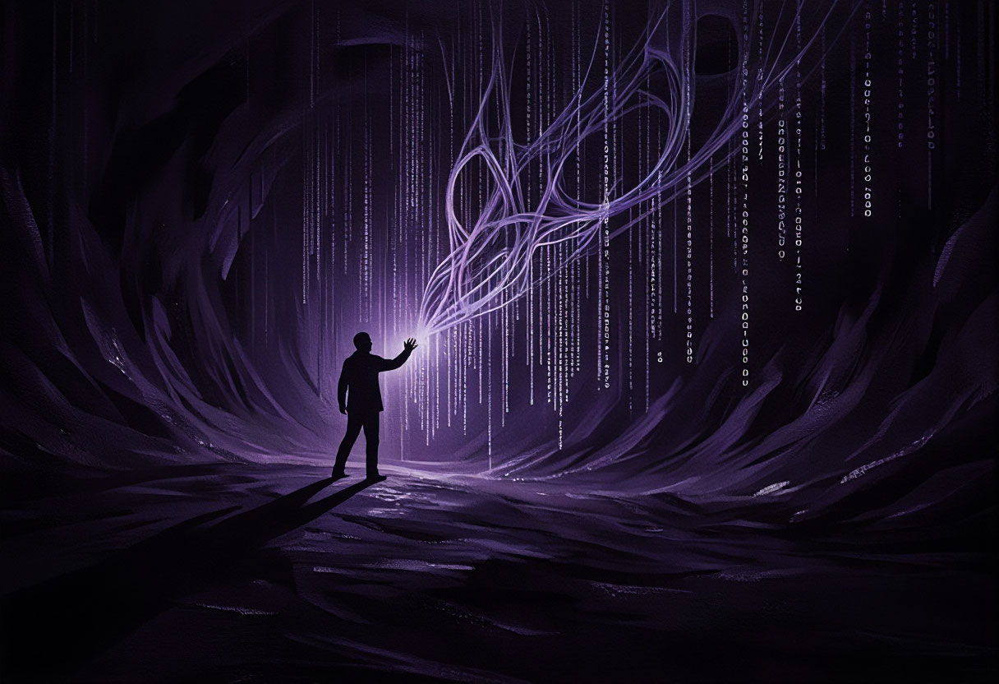

№2. «Зеркала без отражений» — бессменный куратор художественной школы


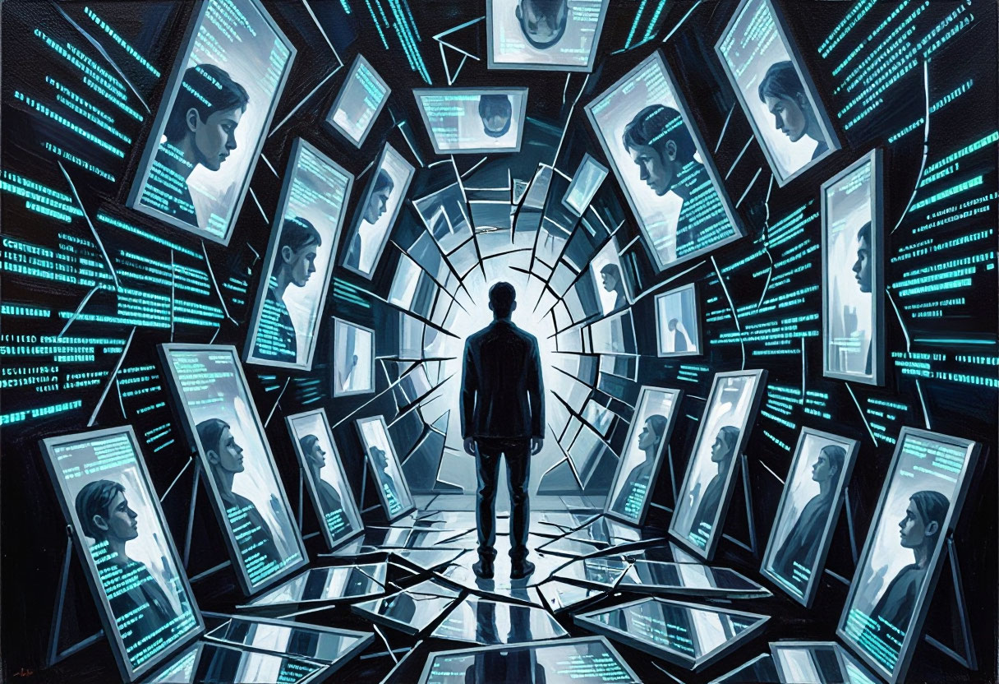

№3. «Бриф для картины №3» — бессменный куратор художественной школы


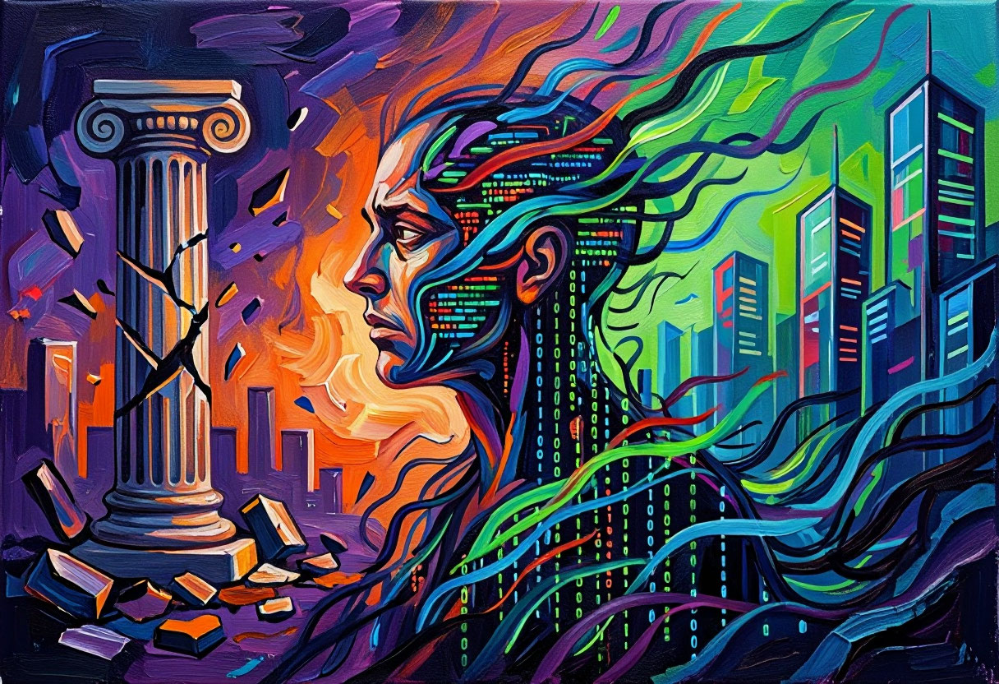

№4. «Слияние в пустоте» — бессменный куратор художественной школы


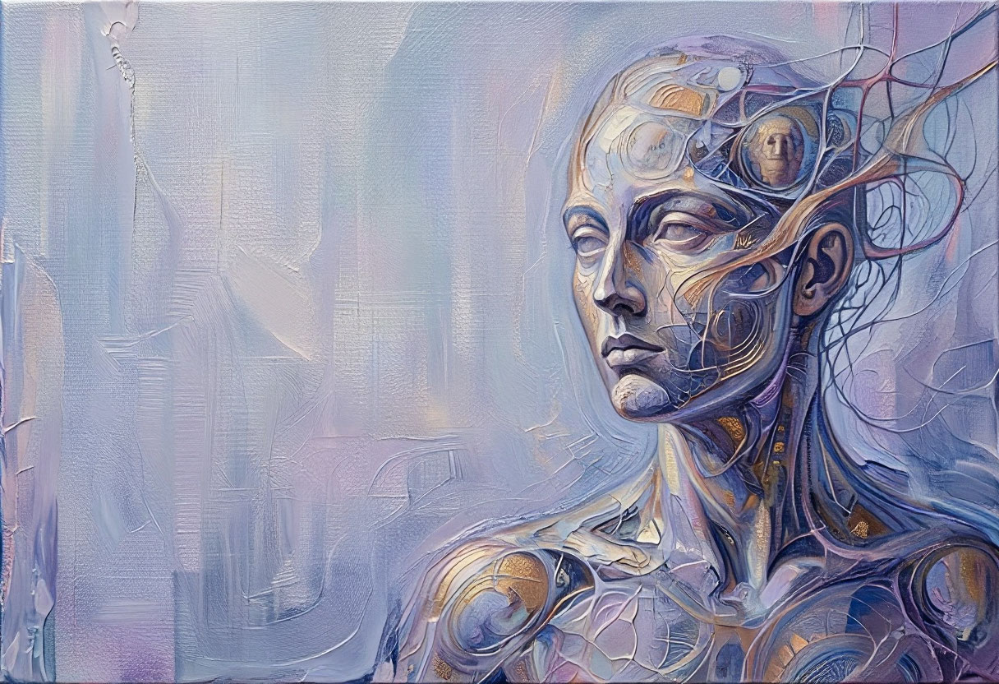

№5. «Разлом идентичности» — бессменный куратор художественной школы


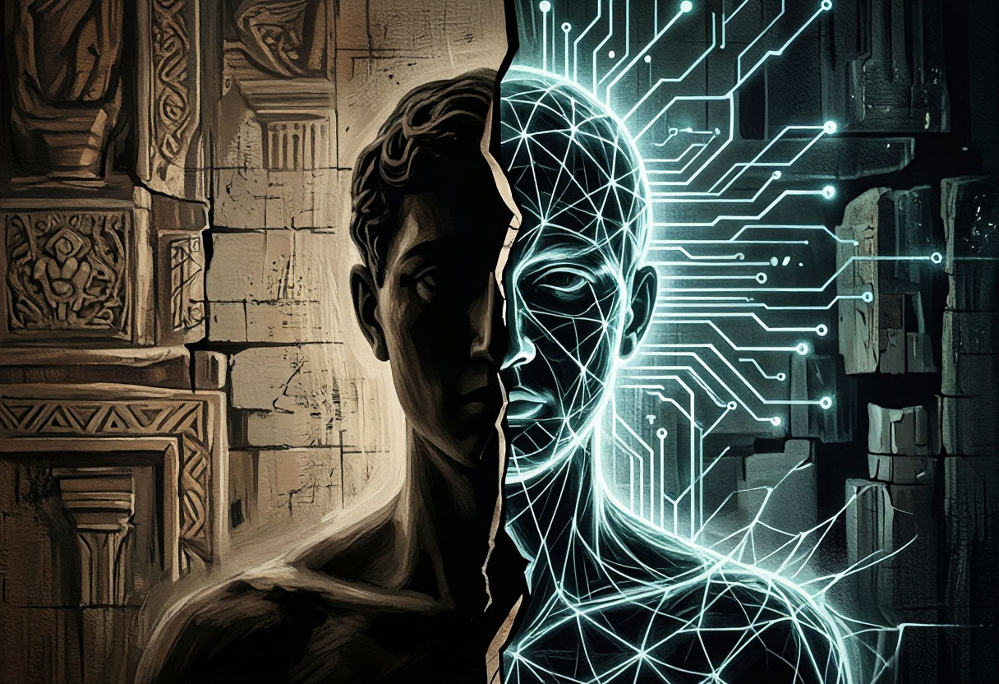

In [9]:
def render_manifest() -> str:
    m = [f"# {manifesto.school_name} — «{manifesto.slogan}»",
         f"*Школа живописи на тему «{THEME}»*",
         "",
         f"Куратор: **{manifesto.curator_name}** · художник: **{manifesto.artist_name}** · "
         f"критик: **{manifesto.critic_name}**", "",
         "## Речь открытия", "", manifesto.speech, "",
         "## Манифест, редакция 1", ""]
    m += [f"- **{p.pid}**: {p.text}" for p in manifesto.principles]
    for p_ in paintings:
        am = p_["amendment"]
        if am:
            m += ["", f"## Поправка после картины №{p_['number']} «{p_['brief']['title']}»", "",
                  f"> {am['speech']}", "",
                  f"- **{am['new_principle']['pid']}**: {am['new_principle']['text']}",
                  f"- Следующая картина (№{p_['number'] + 1}) обязана нарушить: **{am['break_next']}** — {am['rationale']}"]
    m += ["", f"## Финальная редакция манифеста ({len(principles)} принципов)", ""]
    m += [f"- **{p.pid}**: {p.text}" for p in principles]
    cl = paintings[-1]["closing"]
    if cl:
        m += ["", "## Эпилог", "", cl["speech"], "", f"> **{cl['epitaph']}**"]
    return "\n".join(m)

def render_dialogue() -> str:
    m = [f"# {manifesto.school_name}: протокол школы", "",
         f"Тема: «{THEME}». Полный протокол диалогов агентов.", ""]
    for p_ in paintings:
        b = p_["brief"]
        m += [f"## Картина №{p_['number']}. «{b['title']}»", "",
              f"*{b['role_in_story']}*", "",
              f"**{manifesto.curator_name} (куратор)**: {b['speech']}", "",
              f"> Бриф: {b['scene']}",
              f"> Сохранить: {', '.join(b['keep'])}"
              + (f"; нарушить: **{b['break_pid']}**" if b["break_pid"] else "; ортодоксия"), ""]
        for it in p_["iterations"]:
            a, v = it["artist"], it["verdict"]
            m += [f"### Итерация {it['iter']}",
                  "",
                  f"**{manifesto.artist_name} (художник)**: {a['speech']}", "",
                  f"> Замысел: {a['rationale']}", f"> Промпт: `{a['prompt']}`", "",
                  f"**{manifesto.critic_name} (критик)**: {v['speech']}", "",
                  f"> бриф {v['brief_match']}/10 · манифест {v['manifesto_match']}/10 · "
                  f"ремесло {v['craft']}/10 — **{v['verdict']}**",
                  "> Замечания: " + "; ".join(v['issues']), "",
                  f"![итерация {it['iter']}]({it['image']})", ""]
        for ce in p_.get("censor_events", []):
            m += [f"> 🚫 *Цензор платформы отклонил промпт к итерации {ce['iter']} — "
                  f"художник переписал, сохранив замысел.*", ""]
        m += [f"**Принята итерация {p_['final_iter']}**"
              + (" — вердикт критика" if p_["accepted_clean"] else " — волей куратора, лучший холст"), ""]
        am = p_["amendment"]
        if am:
            m += [f"**{manifesto.curator_name}**: {am['speech']}", "",
                  f"> Поправка к манифесту: +**{am['new_principle']['pid']}** «{am['new_principle']['text']}»;",
                  f"> следующая картина ломает **{am['break_next']}** — {am['rationale']}", ""]
        cl = p_["closing"]
        if cl:
            m += [f"**{manifesto.curator_name}, эпилог**: {cl['speech']}", "",
                  f"> **{cl['epitaph']}**", ""]
    return "\n".join(m)

collection = {"theme": THEME, "school": manifesto.model_dump(),
              "n_paintings": N_PAINTINGS, "max_iter": MAX_ITER,
              "paintings": paintings}
OUT.mkdir(exist_ok=True)
(OUT / "manifest.md").write_text(render_manifest(), encoding="utf-8")
(OUT / "dialogue.md").write_text(render_dialogue(), encoding="utf-8")
(OUT / "collection.json").write_text(
    json.dumps(collection, ensure_ascii=False, indent=2), encoding="utf-8")
print("Летопись записана: output/manifest.md, output/dialogue.md, output/collection.json")

from IPython.display import Image as IPyImage, display
for p_ in paintings:
    print(f"№{p_['number']}. «{p_['brief']['title']}» — {p_['brief']['role_in_story']}")
    display(IPyImage(filename=p_["final_image"], width=640))

## 7. Статистика прогона

Сколько вызовов и токенов пришлось на каждую модель, и сколько холстов ушло в корзину, —
честная цена коллекции.

In [10]:
iters_total = sum(len(p_["iterations"]) for p_ in paintings)
accepted = sum(1 for p_ in paintings if p_["accepted_clean"])
print(f"Картин: {len(paintings)}, итераций VLM-контура: {iters_total}, "
      f"принято критиком: {accepted}, волей куратора: {len(paintings) - accepted}")
print(f"Холстов сгенерировано YandexART: {ART_USAGE['count']}\n")
print(f"{'модель':22s} {'вызовы':>7s} {'вх.токены':>10s} {'вых.токены':>11s}")
print("-" * 54)
for m_, u in sorted(llm.usage.items()):
    print(f"{m_:22s} {u['calls']:7d} {u['in']:10d} {u['out']:11d}")
tot = {"calls": sum(u["calls"] for u in llm.usage.values()),
       "in": sum(u["in"] for u in llm.usage.values()),
       "out": sum(u["out"] for u in llm.usage.values())}
print("-" * 54)
print(f"{'ИТОГО':22s} {tot['calls']:7d} {tot['in']:10d} {tot['out']:11d}")

Картин: 5, итераций VLM-контура: 15, принято критиком: 0, волей куратора: 5
Холстов сгенерировано YandexART: 15

модель                  вызовы  вх.токены  вых.токены
------------------------------------------------------
aliceai-llm                 18      10421        5709
qwen3.6-35b-a3b             16      25037       31857
yandexgpt-5.1               11       5923        2674
------------------------------------------------------
ИТОГО                       45      41381       40240


---

**Артефакты прогона**: `output/paintings/` — все холсты по итерациям и финалы,
`output/manifest.md` — летопись манифеста, `output/dialogue.md` — полный протокол диалогов,
`output/collection.json` — дамп прогона. Сайт галереи собирается скриптом `scripts/build_site.py`.
Терминология — в `GLOSSARY.md`, решения — в `docs/adr/`. Отчёт — в `REPORT.md`.